# Role 4 — Cart Behavior & Catalog (Descriptive Analysis)
**Data:** `intent_train.parquet` (train split only, no val/test used to avoid leakage)
**Unit of analysis:** one row = one user session that reached its first add-to-cart.
**Target:** `target_purchased_after_cart` (1 = buyer, 0 = non-buyer).

**Outputs**
- Figures → `reports/cart_analysis/figures/`
- Summary JSON → `reports/cart_analysis/cart_behavior_summary.json`
- Columns report → `reports/cart_analysis/columns_report.csv`

This notebook is **descriptive only** (no modelling).

## 0. Setup

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ---- paths (run the notebook from its own folder or from repo root) ----
CANDIDATES = [os.environ.get("INTENT_TRAIN", ""),
              "data/intent_train.parquet",
              "../../data/intent_train.parquet",
              "intent_train.parquet"]
DATA_PATH = next(p for p in CANDIDATES if p and os.path.exists(p))
REPO_ROOT = os.environ.get("REPO_ROOT", "../..")
OUT_DIR = os.path.join(REPO_ROOT, "reports", "cart_analysis")
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

TARGET = "target_purchased_after_cart"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
C_BUY, C_NO = "#1D9E75", "#B4B2A9"

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight"); plt.show()

def r(x, n=4):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), n)

df = pd.read_parquet(DATA_PATH)
print(DATA_PATH, df.shape)

/mnt/user-data/uploads/intent_train.parquet (590754, 28)


## 1. Columns report (shared with the team on Day 1)

In [2]:
report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
    "example": df.iloc[0].astype(str)
})
report.index.name = "column"
report.to_csv(os.path.join(OUT_DIR, "columns_report.csv"))
report

,dtype,missing_pct,n_unique,example
column,,,,
user_session,str,0.00,590754,a7d4a2b0-eb94-31da-777e-bc656c25c223
user_id,str,0.00,264008,531443237
session_start,"datetime64[ns, UTC]",0.00,557296,2019-12-25 19:35:37+00:00
first_cart_time,"datetime64[ns, UTC]",0.00,554435,2019-12-25 19:35:37+00:00
split,str,0.00,1,train
cart_product_ids_at_first_cart_sec,str,0.00,38724,5870668
cart_category_ids_at_first_cart_sec,str,0.00,556,1487580005671109489
seconds_to_first_cart,int64,0.00,11990,0
views_before_cart,int64,0.00,92,0


**Notes on missing values**
- `avg_viewed_price_before_cart`, `max_viewed_price_before_cart`, `price_ratio_cart_to_view` are missing ~39% — this is **structural**: it happens when the session had no product view before the cart (`has_view_before_cart = 0`). It is not random missingness.
- `avg_cart_price_at_first_cart_sec` is missing only ~0.13%.

In [3]:
no_view = df.has_view_before_cart == 0
print("share sessions with no view:", round(no_view.mean()*100, 2), "%")
print("missing viewed price when no view:", df.loc[no_view, "avg_viewed_price_before_cart"].isna().mean())
print("missing viewed price when has view:", df.loc[~no_view, "avg_viewed_price_before_cart"].isna().mean())

share sessions with no view: 39.37 %
missing viewed price when no view: 1.0
missing viewed price when has view: 0.000943683324445586


## 2. Overview & target balance

sessions=590,754 users=264,008 purchase rate after cart=12.57%
period: 2019-10-02 00:00:03+00:00 -> 2019-12-31 23:54:22+00:00


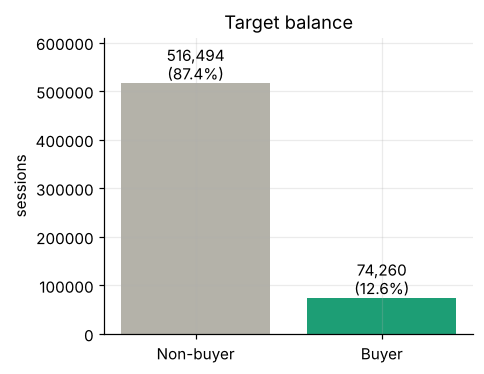

In [4]:
n = len(df); n_users = df.user_id.nunique()
buy_rate = df[TARGET].mean()
print(f"sessions={n:,} users={n_users:,} purchase rate after cart={buy_rate:.2%}")
print("period:", df.session_start.min(), "->", df.session_start.max())
assert df.user_session.is_unique

fig, ax = plt.subplots(figsize=(4.5,3.5))
vc = df[TARGET].value_counts().sort_index()
ax.bar(["Non-buyer","Buyer"], vc.values, color=[C_NO, C_BUY])
for i,v in enumerate(vc.values): ax.text(i, v, f"{v:,}\n({v/n:.1%})", ha="center", va="bottom")
ax.set_ylabel("sessions"); ax.set_title("Target balance"); ax.set_ylim(0, vc.max()*1.18)
savefig("01_target_balance.png")

## 3. Pre-cart behavior: buyer vs non-buyer

In [5]:
df["is_buyer"] = df[TARGET].map({1:"buyer", 0:"non_buyer"})
metrics = ["seconds_to_first_cart","views_before_cart","unique_products_viewed_before_cart",
           "unique_categories_viewed_before_cart","unique_brands_viewed_before_cart",
           "removes_before_cart","unique_products_removed_before_cart","cart_events_at_first_cart_sec",
           "avg_cart_price_at_first_cart_sec","avg_viewed_price_before_cart","price_ratio_cart_to_view",
           "user_prior_sessions","user_prior_purchase_sessions"]
flags = ["has_view_before_cart","has_multi_products_at_first_cart_sec","any_cart_brand_at_first_cart_sec"]

rows = []
for m in metrics:
    g = df.groupby("is_buyer")[m]
    rows.append({"feature": m,
                 "buyer_mean": g.mean()["buyer"], "non_buyer_mean": g.mean()["non_buyer"],
                 "buyer_median": g.median()["buyer"], "non_buyer_median": g.median()["non_buyer"]})
cmp_num = pd.DataFrame(rows)
cmp_num["median_diff"] = cmp_num.buyer_median - cmp_num.non_buyer_median
cmp_num.round(3)

,feature,buyer_mean,non_buyer_mean,buyer_median,non_buyer_median,median_diff
0,seconds_to_first_cart,2735.655,1828.836,25.00,13.00,12.00
1,views_before_cart,1.383,1.206,1.00,1.00,0.00
2,unique_products_viewed_before_cart,1.186,1.082,1.00,1.00,0.00
3,unique_categories_viewed_before_cart,0.785,0.786,1.00,1.00,0.00
4,unique_brands_viewed_before_cart,0.506,0.492,0.00,0.00,0.00
5,removes_before_cart,0.936,0.661,0.00,0.00,0.00
6,unique_products_removed_before_cart,0.628,0.434,0.00,0.00,0.00
7,cart_events_at_first_cart_sec,1.018,1.009,1.00,1.00,0.00
8,avg_cart_price_at_first_cart_sec,9.292,7.805,4.97,4.44,0.53
9,avg_viewed_price_before_cart,12.014,9.615,5.71,4.86,0.85


In [6]:
cmp_flag = df.groupby("is_buyer")[flags].mean().T
cmp_flag.columns = ["buyer_share","non_buyer_share"] if cmp_flag.columns[0]=="buyer" else ["non_buyer_share","buyer_share"]
cmp_flag = cmp_flag[["buyer_share","non_buyer_share"]]
cmp_flag["lift_pp"] = (cmp_flag.buyer_share - cmp_flag.non_buyer_share) * 100
cmp_flag.round(4)

,buyer_share,non_buyer_share,lift_pp
has_view_before_cart,0.5682,0.6118,-4.3565
has_multi_products_at_first_cart_sec,0.0010,0.0012,-0.0206
any_cart_brand_at_first_cart_sec,0.5975,0.5886,0.8904


### 3.1 Conversion rate by key pre-cart signals

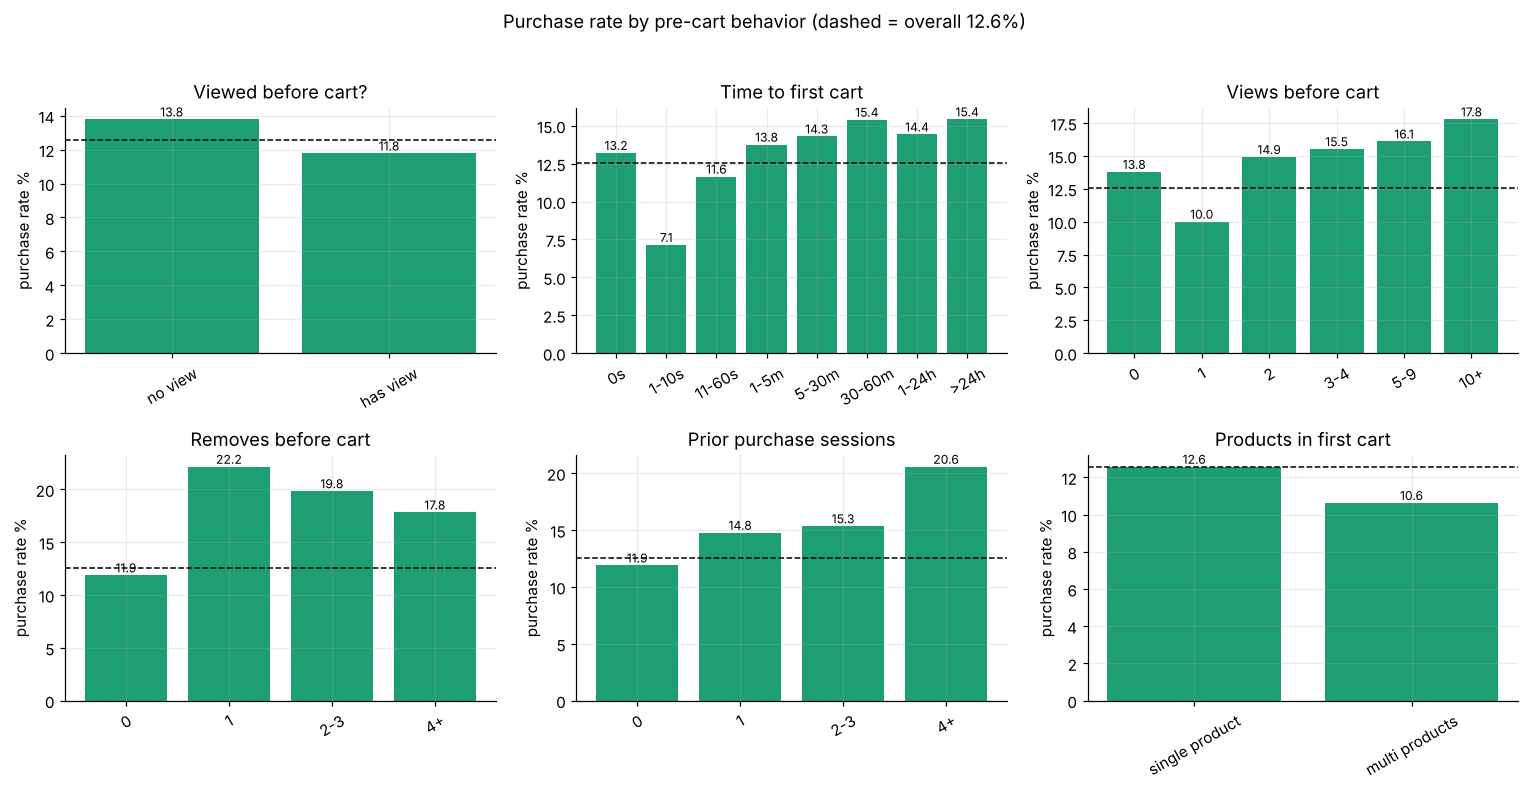

(                       sessions  conversion
 seconds_to_first_cart                      
 0s                       211460    0.132086
 1-10s                     64102    0.071417
 11-60s                   104223    0.116462
 1-5m                     123428    0.137554
 5-30m                     68431    0.142932
 30-60m                     8047    0.153970
 1-24h                      9163    0.144276
 >24h                       1900    0.154211,
                    sessions  conversion
 views_before_cart                      
 0                    232583    0.137865
 1                    242577    0.100005
 2                     50492    0.149152
 3-4                   35594    0.155139
 5-9                   21572    0.160949
 10+                    7936    0.177797,
                      sessions  conversion
 removes_before_cart                      
 0                      535369    0.118731
 1                       10965    0.221523
 2-3                     17283    0.198403
 4+  

In [7]:
def conv_by(col, bins=None, labels=None):
    s = df[col] if bins is None else pd.cut(df[col], bins=bins, labels=labels, right=True, include_lowest=True)
    t = df.groupby(s, observed=True)[TARGET].agg(["size","mean"]).rename(columns={"size":"sessions","mean":"conversion"})
    return t

# time to first cart
tb = [-1,0,10,60,300,1800,3600,86400,np.inf]
tl = ["0s","1-10s","11-60s","1-5m","5-30m","30-60m","1-24h",">24h"]
t_sec = conv_by("seconds_to_first_cart", tb, tl)
# views before cart
vb = [-1,0,1,2,4,9,np.inf]; vl = ["0","1","2","3-4","5-9","10+"]
t_views = conv_by("views_before_cart", vb, vl)
# removes before cart
rb = [-1,0,1,3,np.inf]; rl = ["0","1","2-3","4+"]
t_rem = conv_by("removes_before_cart", rb, rl)
# prior purchases
pb = [-1,0,1,3,np.inf]; pl = ["0","1","2-3","4+"]
t_prior = conv_by("user_prior_purchase_sessions", pb, pl)
t_hasview = conv_by("has_view_before_cart"); t_hasview.index = ["no view","has view"]
t_multi = conv_by("has_multi_products_at_first_cart_sec"); t_multi.index = ["single product","multi products"]

fig, axes = plt.subplots(2,3, figsize=(14,7))
for ax,(t,title) in zip(axes.ravel(), [(t_hasview,"Viewed before cart?"),(t_sec,"Time to first cart"),
        (t_views,"Views before cart"),(t_rem,"Removes before cart"),(t_prior,"Prior purchase sessions"),(t_multi,"Products in first cart")]):
    ax.bar(t.index.astype(str), t.conversion*100, color=C_BUY)
    ax.axhline(buy_rate*100, color="k", ls="--", lw=1); ax.set_title(title); ax.set_ylabel("purchase rate %")
    for i,v in enumerate(t.conversion*100): ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"Purchase rate by pre-cart behavior (dashed = overall {buy_rate:.1%})", y=1.02)
savefig("02_buyer_vs_nonbuyer_behavior.png")
t_sec, t_views, t_rem, t_prior

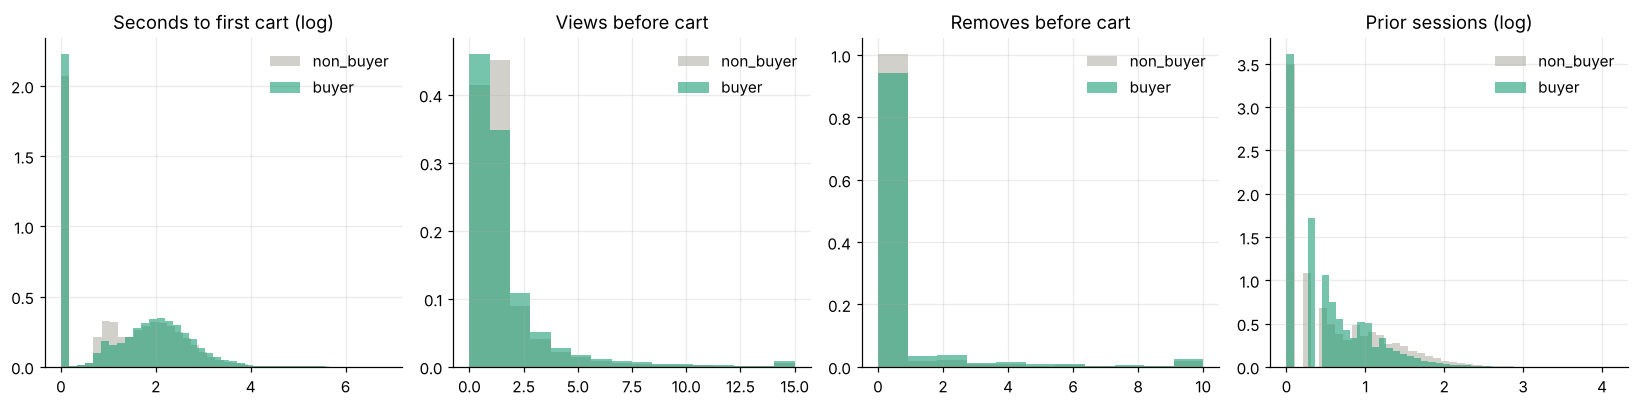

In [8]:
# Buyer vs non-buyer: distribution comparison (median-based, robust to outliers)
fig, axes = plt.subplots(1,4, figsize=(15,3.8))
for ax,(col,title,clip) in zip(axes, [("seconds_to_first_cart","Seconds to first cart (log)",None),
        ("views_before_cart","Views before cart",15),("removes_before_cart","Removes before cart",10),
        ("user_prior_sessions","Prior sessions (log)",None)]):
    for lab,color in [("non_buyer",C_NO),("buyer",C_BUY)]:
        x = df.loc[df.is_buyer==lab, col]
        if clip: x = x.clip(upper=clip); ax.hist(x, bins=clip+1, alpha=.6, color=color, density=True, label=lab)
        else:    ax.hist(np.log10(x+1), bins=40, alpha=.6, color=color, density=True, label=lab)
    ax.set_title(title); ax.legend(frameon=False)
savefig("03_distributions_buyer_vs_nonbuyer.png")

### 3.2 When do sessions convert? (hour / weekday)

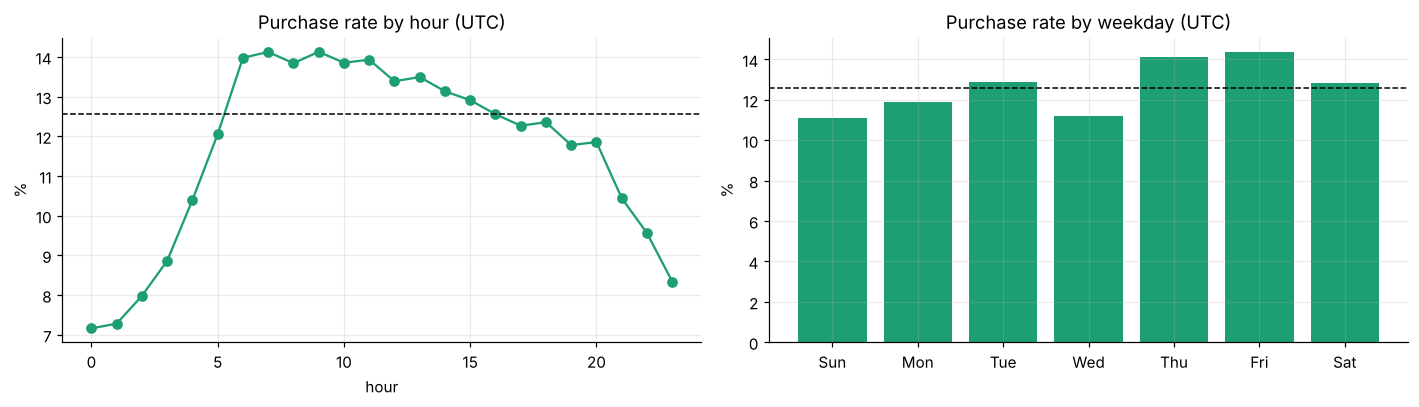

session_start        0      1   2   3   4    5      6
day_of_week_utc                                      
0                   14     14  36  50  77  276  86366
1                88831     17  27  37  43   72    315
2                  303  78254  21  14  22   36     78


In [9]:
dow_names = ["Sun","Mon","Tue","Wed","Thu","Fri","Sat"]  # verified: day_of_week_utc 0 = Sunday
t_hour = conv_by("hour_of_day_utc"); t_dow = conv_by("day_of_week_utc"); t_dow.index = dow_names
fig, axes = plt.subplots(1,2, figsize=(13,3.8))
axes[0].plot(t_hour.index, t_hour.conversion*100, marker="o", color=C_BUY); axes[0].set_title("Purchase rate by hour (UTC)"); axes[0].set_xlabel("hour")
axes[1].bar(t_dow.index, t_dow.conversion*100, color=C_BUY); axes[1].set_title("Purchase rate by weekday (UTC)")
for ax in axes: ax.axhline(buy_rate*100, color="k", ls="--", lw=1); ax.set_ylabel("%")
savefig("04_time_patterns.png")
# Encoding check: day_of_week_utc == 0 is Sunday (pandas dayofweek 6). Hour/day are computed at first_cart_time (~0.3% differ from session_start).
print(pd.crosstab(df.day_of_week_utc, df.session_start.dt.dayofweek).iloc[:3])

## 4. Catalog & brands
The file has **no brand name/ID column** — only brand *counts* (`unique_brands_viewed_before_cart`) and a flag (`any_cart_brand_at_first_cart_sec`). Brand analysis is therefore at the *brand-presence* level. Catalog analysis uses `cart_category_ids_at_first_cart_sec` and `cart_product_ids_at_first_cart_sec` (IDs, no names).

In [10]:
# brand presence
t_brand_cart = conv_by("any_cart_brand_at_first_cart_sec"); t_brand_cart.index = ["no brand","branded"]
bb = [-1,0,1,2,np.inf]; bl = ["0","1","2","3+"]
t_brand_view = conv_by("unique_brands_viewed_before_cart", bb, bl)

# multi-value fields: check separators
multi_cat = df.cart_category_ids_at_first_cart_sec.str.contains(r"[,;|]").mean()
multi_prod = df.cart_product_ids_at_first_cart_sec.str.contains(r"[,;|]").mean()
print("multi-category rows:", round(multi_cat*100,2), "%  | multi-product rows:", round(multi_prod*100,3), "%")

multi-category rows: 0.02 %  | multi-product rows: 0.116 %


In [11]:
# Use the single primary category / product (multi-value rows are rare; first id is kept)
df["cart_category"] = df.cart_category_ids_at_first_cart_sec.str.split(r"[,;|]").str[0]
df["cart_product"]  = df.cart_product_ids_at_first_cart_sec.str.split(r"[,;|]").str[0]

MIN_SUP = 500
cat = df.groupby("cart_category")[TARGET].agg(sessions="size", purchases="sum", conversion="mean").sort_values("sessions", ascending=False)
cat["share_of_sessions"] = cat.sessions / n
cat["cum_share"] = cat.share_of_sessions.cumsum()
top_cat = cat.head(15)
best_cat = cat[cat.sessions>=MIN_SUP].sort_values("conversion", ascending=False).head(10)
worst_cat = cat[cat.sessions>=MIN_SUP].sort_values("conversion").head(10)

prod = df.groupby("cart_product")[TARGET].agg(sessions="size", purchases="sum", conversion="mean").sort_values("sessions", ascending=False)
prod["share_of_sessions"] = prod.sessions / n
top_prod = prod.head(15)
print("categories:", len(cat), "| products:", len(prod))
print("top10 categories cover", round(cat.share_of_sessions.head(10).sum()*100,1), "% of sessions")
print("top50 products cover", round(prod.share_of_sessions.head(50).sum()*100,1), "% of sessions")
top_cat.round(4)

categories: 463 | products: 38101
top10 categories cover 29.7 % of sessions
top50 products cover 10.1 % of sessions


,sessions,purchases,conversion,share_of_sessions,cum_share
cart_category,,,,,
1487580005092295511,28094,3829,0.1363,0.0476,0.0476
1487580007675986893,21887,1801,0.0823,0.0370,0.0846
1487580006317032337,20455,2516,0.1230,0.0346,0.1192
1602943681873052386,19586,2301,0.1175,0.0332,0.1524
1487580005595612013,16564,1455,0.0878,0.0280,0.1804
1487580008246412266,15650,2505,0.1601,0.0265,0.2069
1487580005671109489,15226,1533,0.1007,0.0258,0.2327
1487580005268456287,14690,1923,0.1309,0.0249,0.2576
1487580013841613016,13345,1885,0.1413,0.0226,0.2801


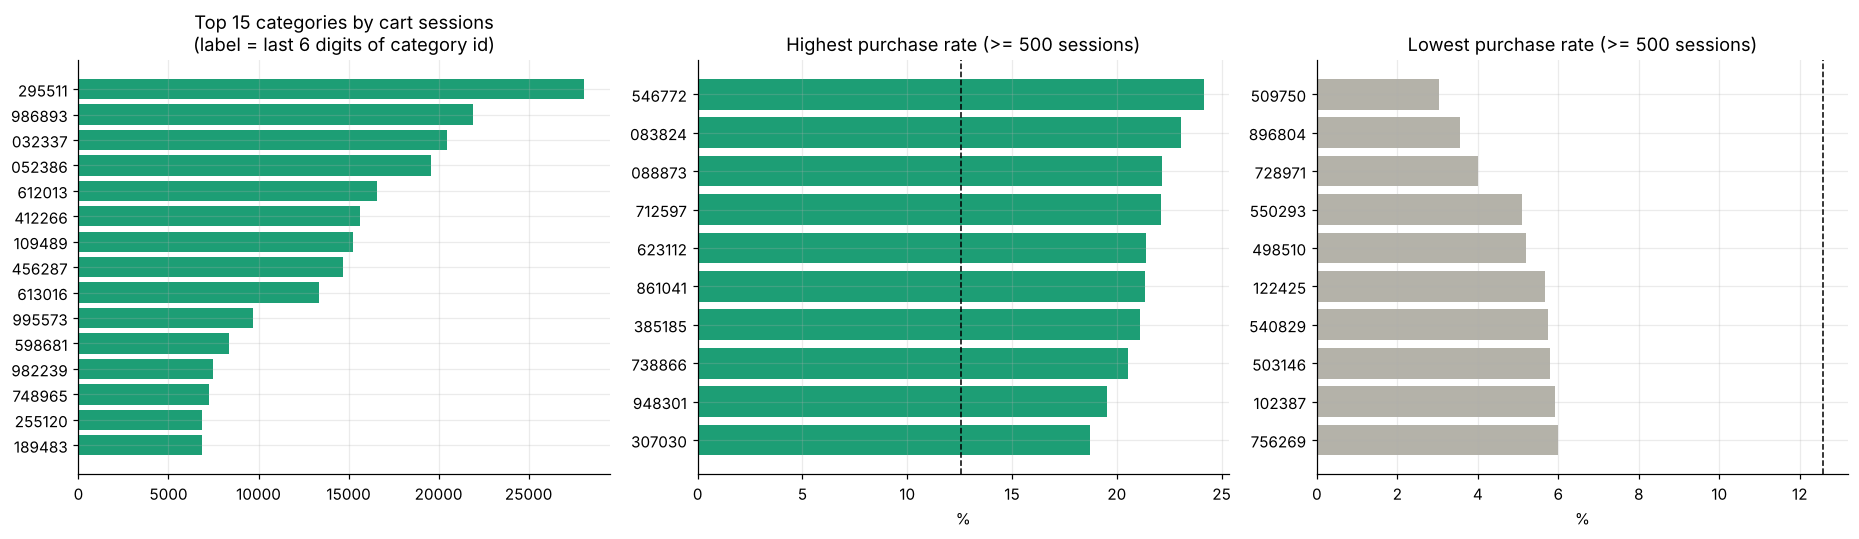

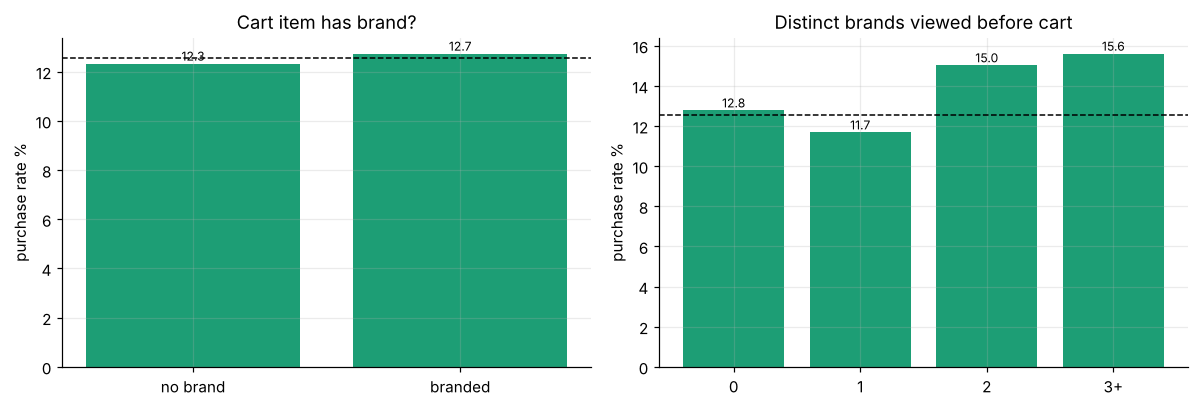

(          sessions  conversion
 no brand    242364    0.123319
 branded     348390    0.127363,
                                   sessions  conversion
 unique_brands_viewed_before_cart                      
 0                                   357992    0.127810
 1                                   195790    0.116839
 2                                    24505    0.150296
 3+                                   12467    0.156092)

In [12]:
fig, axes = plt.subplots(1,3, figsize=(17,5))
t = top_cat.iloc[::-1]
axes[0].barh([c[-6:] for c in t.index.astype(str)], t.sessions, color=C_BUY); axes[0].set_title("Top 15 categories by cart sessions\n(label = last 6 digits of category id)")
t = best_cat.iloc[::-1]
axes[1].barh([c[-6:] for c in t.index.astype(str)], t.conversion*100, color=C_BUY); axes[1].set_title(f"Highest purchase rate (>= {MIN_SUP} sessions)"); axes[1].set_xlabel("%")
t = worst_cat.iloc[::-1]
axes[2].barh([c[-6:] for c in t.index.astype(str)], t.conversion*100, color=C_NO); axes[2].set_title(f"Lowest purchase rate (>= {MIN_SUP} sessions)"); axes[2].set_xlabel("%")
for ax in axes[1:]: ax.axvline(buy_rate*100, color="k", ls="--", lw=1)
savefig("05_catalog_categories.png")

fig, axes = plt.subplots(1,2, figsize=(11,3.8))
for ax,(t,title) in zip(axes,[(t_brand_cart,"Cart item has brand?"),(t_brand_view,"Distinct brands viewed before cart")]):
    ax.bar(t.index.astype(str), t.conversion*100, color=C_BUY); ax.axhline(buy_rate*100, color="k", ls="--", lw=1)
    ax.set_title(title); ax.set_ylabel("purchase rate %")
    for i,v in enumerate(t.conversion*100): ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
savefig("06_brand_presence.png")
t_brand_cart, t_brand_view

## 5. Cart behavior by price band (descriptive)

In [13]:
price = df["avg_cart_price_at_first_cart_sec"]
q = price.quantile([1/3, 2/3]).values
labels = ["Low", "Mid", "High"]
df["price_band"] = pd.cut(price, bins=[-np.inf, q[0], q[1], np.inf], labels=labels)
print("thresholds:", q.round(2), "| missing price:", price.isna().sum())

agg = df.groupby("price_band", observed=True).agg(
    sessions=(TARGET,"size"), conversion=(TARGET,"mean"),
    price_min=("avg_cart_price_at_first_cart_sec","min"), price_median=("avg_cart_price_at_first_cart_sec","median"), price_max=("avg_cart_price_at_first_cart_sec","max"),
    median_seconds_to_cart=("seconds_to_first_cart","median"),
    mean_views=("views_before_cart","mean"), mean_removes=("removes_before_cart","mean"),
    share_has_view=("has_view_before_cart","mean"), share_multi_product=("has_multi_products_at_first_cart_sec","mean"),
    share_branded=("any_cart_brand_at_first_cart_sec","mean"),
    median_prior_sessions=("user_prior_sessions","median"), mean_prior_purchases=("user_prior_purchase_sessions","mean"),
    median_price_ratio=("price_ratio_cart_to_view","median"))
agg.round(3)

thresholds: [2.94 5.95] | missing price: 745


,sessions,conversion,price_min,price_median,price_max,median_seconds_to_cart,mean_views,mean_removes,share_has_view,share_multi_product,share_branded,median_prior_sessions,mean_prior_purchases,median_price_ratio
price_band,,,,,,,,,,,,,,
Low,196790,0.112,0.05,1.59,2.94,13.0,1.182,0.835,0.573,0.002,0.606,3.0,0.364,1.0
Mid,196630,0.113,2.95,4.44,5.95,14.0,1.253,0.700,0.616,0.001,0.573,2.0,0.367,1.0
High,196589,0.153,5.97,10.32,327.78,16.0,1.251,0.552,0.630,0.001,0.592,1.0,0.342,1.0


In [14]:
# cart price vs viewed price (buying "up" or "down")
d = df.dropna(subset=["price_ratio_cart_to_view"]).copy()
d["move"] = pd.cut(d.price_ratio_cart_to_view, [0, .9, 1.1, np.inf], labels=["cheaper than viewed","same","pricier than viewed"])
t_move = d.groupby("move", observed=True)[TARGET].agg(sessions="size", conversion="mean")
t_move["share"] = t_move.sessions / t_move.sessions.sum()
t_move.round(4)

,sessions,conversion,share
move,,,
cheaper than viewed,75687,0.1413,0.2116
same,236094,0.1034,0.6601
pricier than viewed,45894,0.1537,0.1283


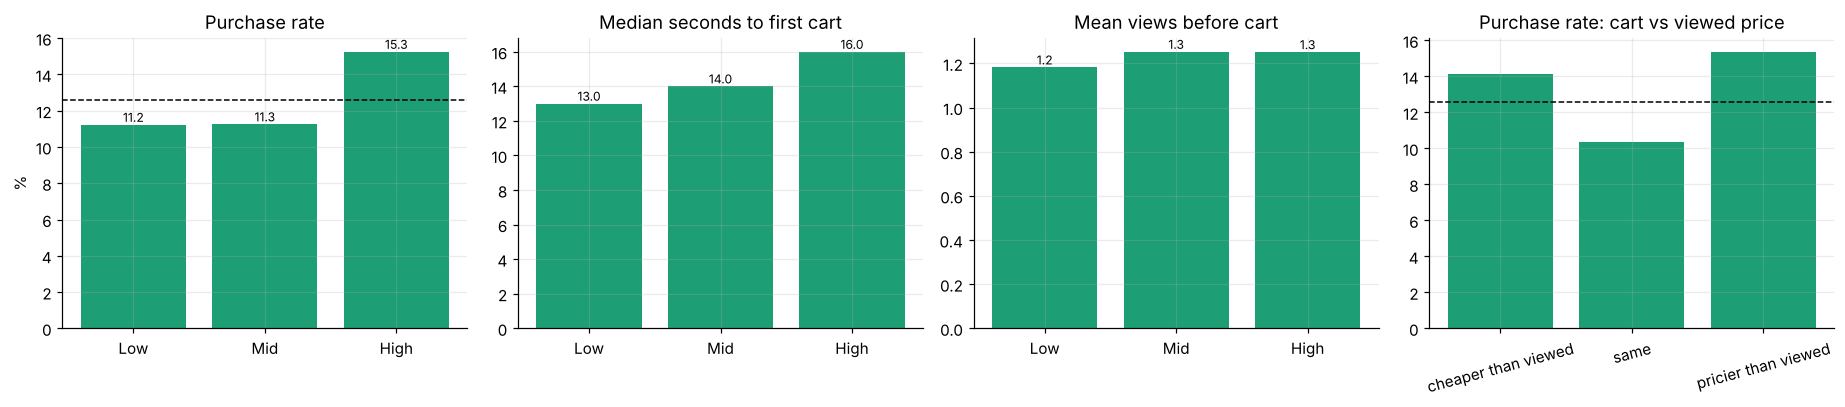

has_view,has view,no view
price_band,,
Low,10.24,12.55
Mid,10.11,13.09
High,14.82,15.98


In [15]:
fig, axes = plt.subplots(1,4, figsize=(17,3.8))
b = agg
axes[0].bar(b.index.astype(str), b.conversion*100, color=C_BUY); axes[0].set_title("Purchase rate"); axes[0].set_ylabel("%")
axes[1].bar(b.index.astype(str), b.median_seconds_to_cart, color=C_BUY); axes[1].set_title("Median seconds to first cart")
axes[2].bar(b.index.astype(str), b.mean_views, color=C_BUY); axes[2].set_title("Mean views before cart")
axes[3].bar(t_move.index.astype(str), t_move.conversion*100, color=C_BUY); axes[3].set_title("Purchase rate: cart vs viewed price"); axes[3].tick_params(axis="x", rotation=15)
axes[0].axhline(buy_rate*100, color="k", ls="--", lw=1); axes[3].axhline(buy_rate*100, color="k", ls="--", lw=1)
for ax in axes[:3]:
    for i,v in enumerate(ax.patches): ax.text(v.get_x()+v.get_width()/2, v.get_height(), f"{v.get_height():.1f}", ha="center", va="bottom", fontsize=8)
savefig("07_price_bands.png")

# band x pre-cart signal
pv = df.assign(has_view=df.has_view_before_cart.map({0:"no view",1:"has view"})).pivot_table(index="price_band", columns="has_view", values=TARGET, aggfunc="mean", observed=True)*100
pv.round(2)

## 6. Build `cart_behavior_summary.json`

In [16]:
def tbl(t, label="bucket"):
    return [{label: str(i), "sessions": int(rw.sessions), "purchase_rate": r(rw.conversion)} for i, rw in t.iterrows()]

summary = {
  "meta": {
    "source_file": "intent_train.parquet", "split": "train",
    "n_sessions": int(n), "n_users": int(n_users),
    "period_start": str(df.session_start.min()), "period_end": str(df.session_start.max()),
    "target_column": TARGET, "overall_purchase_rate": r(buy_rate),
    "n_buyers": int(df[TARGET].sum()), "n_non_buyers": int((1-df[TARGET]).sum()),
    "notes": ["Descriptive analysis only; train split only.",
              "avg_viewed_price/max_viewed_price/price_ratio are NaN when there was no view before cart (structural).",
              "No brand name column exists; brand analysis is presence-based.",
              "Category/product ids are raw ids (no names in the data)."]
  },
  "pre_cart_behavior": {
    "numeric_comparison": [
       {"feature": x.feature, "buyer_mean": r(x.buyer_mean), "non_buyer_mean": r(x.non_buyer_mean),
        "buyer_median": r(x.buyer_median), "non_buyer_median": r(x.non_buyer_median)} for x in cmp_num.itertuples()],
    "flag_comparison": [
       {"feature": i, "buyer_share": r(x.buyer_share), "non_buyer_share": r(x.non_buyer_share)} for i, x in cmp_flag.iterrows()],
    "purchase_rate_by_has_view": tbl(t_hasview),
    "purchase_rate_by_seconds_to_first_cart": tbl(t_sec),
    "purchase_rate_by_views_before_cart": tbl(t_views),
    "purchase_rate_by_removes_before_cart": tbl(t_rem),
    "purchase_rate_by_prior_purchase_sessions": tbl(t_prior),
    "purchase_rate_by_multi_product_cart": tbl(t_multi),
    "purchase_rate_by_hour_utc": [{"hour": int(i), "sessions": int(x.sessions), "purchase_rate": r(x.conversion)} for i, x in t_hour.iterrows()],
    "purchase_rate_by_weekday_utc": tbl(t_dow, "weekday")
  },
  "catalog_and_brands": {
    "n_categories": int(len(cat)), "n_products": int(len(prod)),
    "top10_categories_share_of_sessions": r(cat.share_of_sessions.head(10).sum()),
    "top50_products_share_of_sessions": r(prod.share_of_sessions.head(50).sum()),
    "min_sessions_for_rate_ranking": MIN_SUP,
    "top_categories_by_volume": [{"category_id": str(i), "sessions": int(x.sessions), "share": r(x.share_of_sessions), "purchase_rate": r(x.conversion)} for i, x in top_cat.iterrows()],
    "highest_purchase_rate_categories": [{"category_id": str(i), "sessions": int(x.sessions), "purchase_rate": r(x.conversion)} for i, x in best_cat.iterrows()],
    "lowest_purchase_rate_categories": [{"category_id": str(i), "sessions": int(x.sessions), "purchase_rate": r(x.conversion)} for i, x in worst_cat.iterrows()],
    "top_products_by_volume": [{"product_id": str(i), "sessions": int(x.sessions), "share": r(x.share_of_sessions), "purchase_rate": r(x.conversion)} for i, x in top_prod.iterrows()],
    "brand_presence": {
       "cart_item_has_brand": tbl(t_brand_cart),
       "distinct_brands_viewed_before_cart": tbl(t_brand_view)}
  },
  "price_band_cart_behavior": {
    "price_column": "avg_cart_price_at_first_cart_sec",
    "band_method": "terciles of avg cart price (equal-size bands)",
    "thresholds": {"low_max": r(q[0], 2), "mid_max": r(q[1], 2)},
    "bands": [{"band": str(i), "sessions": int(x.sessions), "purchase_rate": r(x.conversion),
               "price_min": r(x.price_min,2), "price_median": r(x.price_median,2), "price_max": r(x.price_max,2),
               "median_seconds_to_first_cart": r(x.median_seconds_to_cart,1), "mean_views_before_cart": r(x.mean_views),
               "mean_removes_before_cart": r(x.mean_removes), "share_has_view": r(x.share_has_view),
               "share_multi_product_cart": r(x.share_multi_product), "share_branded": r(x.share_branded),
               "median_prior_sessions": r(x.median_prior_sessions,1), "mean_prior_purchase_sessions": r(x.mean_prior_purchases)}
              for i, x in agg.iterrows()],
    "cart_vs_viewed_price": [{"move": str(i), "sessions": int(x.sessions), "share": r(x.share), "purchase_rate": r(x.conversion)} for i, x in t_move.iterrows()]
  }
}
with open(os.path.join(OUT_DIR, "cart_behavior_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("saved JSON. top-level keys:", list(summary))

saved JSON. top-level keys: ['meta', 'pre_cart_behavior', 'catalog_and_brands', 'price_band_cart_behavior']


## 7. Key findings

In [17]:
hv = t_hasview.conversion
print(f"1) Overall purchase rate after cart: {buy_rate:.1%} (strong class imbalance).")
print(f"2) Sessions with a product view before cart convert at {hv['has view']:.1%} vs {hv['no view']:.1%} without a view.")
print(f"3) Median time to first cart — buyers: {cmp_num.set_index('feature').loc['seconds_to_first_cart','buyer_median']:.0f}s, non-buyers: {cmp_num.set_index('feature').loc['seconds_to_first_cart','non_buyer_median']:.0f}s.")
print(f"4) Prior purchase history: rate {t_prior.conversion.iloc[0]:.1%} (0 prior) -> {t_prior.conversion.iloc[-1]:.1%} (4+ prior).")
print("5) Price bands:", {str(k): f"{v:.1%}" for k,v in agg.conversion.items()})

1) Overall purchase rate after cart: 12.6% (strong class imbalance).
2) Sessions with a product view before cart convert at 11.8% vs 13.8% without a view.
3) Median time to first cart — buyers: 25s, non-buyers: 13s.
4) Prior purchase history: rate 11.9% (0 prior) -> 20.6% (4+ prior).
5) Price bands: {'Low': '11.2%', 'Mid': '11.3%', 'High': '15.3%'}
